# WFS spectrograms

Load one channel from a `.wfs` file and display two spectrograms: mean-pooled and max-pooled. Every overlapping analysis window contributes to the requested modes; the only difference is aggregation within each display column.

Requires the installed `decode-wfs`, `numpy`, `scipy`, and `matplotlib` packages. Run cells in order. Only the filepath is prompted; edit all other settings below.


## Imports


In [21]:
from pathlib import Path
import operator

import numpy as np
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view
from scipy.signal import get_window, periodogram
from decode_wfs import load_continuous


## Functions

All functions are defined here, before configuration and data loading.


In [22]:
def select_time_range(samples, times, *, start_time=None, end_time=None):
    """Select [start_time, end_time) on the loader's increasing time axis.

    None leaves that bound unrestricted. Return a signal slice and its actual
    first-sample time in seconds, preserving the recording's time coordinates.
    The loader's timestamps are assumed to be uniformly sampled and increasing.
    """
    samples = np.asarray(samples)
    times = np.asarray(times)
    if samples.ndim != 1 or times.ndim != 1 or samples.size != times.size:
        raise ValueError("samples and times must be equal-length 1-D arrays.")
    if times.size < 2:
        raise ValueError("At least two samples are required.")
    for bound in (start_time, end_time):
        if bound is not None and not np.isfinite(bound):
            raise ValueError("Time bounds must be finite or None.")
    if start_time is not None and end_time is not None and end_time <= start_time:
        raise ValueError("end_time must be greater than start_time.")

    first = 0 if start_time is None else int(np.searchsorted(times, start_time))
    stop = times.size if end_time is None else int(np.searchsorted(times, end_time))
    if stop - first < 2:
        raise ValueError("The selected interval must contain at least two samples.")
    return samples[first:stop], float(times[first])


In [23]:
def compute_spectrogram(
    signal,
    fs,
    *,
    modes=("mean", "max"),
    nperseg=4096,
    noverlap=None,
    n_time_bins=1000,
    batch_size=128,
    window="hann",
    detrend="constant",
    boundary="zeros",
    time_offset=0.0,
):
    """Return frequencies (Hz), time edges (s), and linear power by mode.

    Each matrix has shape (frequency bins, display columns), in V²/Hz for
    voltage input. All requested modes consume the same one-sided, density-
    scaled window spectra calculated by scipy.signal.periodogram.

    modes: any nonempty subset of ("mean", "max"); unknown names raise an error.
    nperseg: window length in samples, capped to the signal length.
    noverlap: overlapping samples; None uses half the actual window length.
    n_time_bins: target columns, capped to the number of analysis windows.
    batch_size: analysis windows per batch; affects working RAM, not resolution.
    window: SciPy window name/tuple, or a real array of length nperseg.
            Named windows use SciPy's periodic (FFT) convention.
    detrend: "constant" subtracts each window's mean; False disables detrending.
    boundary: "zeros" centers windows at 0, hop, ... < len(signal), padding
              beyond the selected interval. None uses only complete windows.
    time_offset: recording time of signal[0], in seconds.

    Windows are assigned to equal-width display columns by their center times.
    With zero padding, edges span the entire selected interval [0, N/fs).
    With complete windows only, edges span the window centers plus half a hop
    on either side, so the plotted time range excludes unanalyzed boundaries.

    Mean pooling averages linear power, weighting every window equally.
    Max pooling takes the maximum separately at every frequency. A max column
    can combine peaks from different windows; it is not an average spectrum.
    """
    signal = np.asarray(signal)
    if (
        signal.ndim != 1
        or signal.size < 2
        or np.iscomplexobj(signal)
        or not np.issubdtype(signal.dtype, np.number)
    ):
        raise ValueError("signal must be a real numeric 1-D array with at least two samples.")
    fs = float(fs)
    time_offset = float(time_offset)
    if not np.isfinite(fs) or fs <= 0:
        raise ValueError("fs must be positive and finite.")
    if not np.isfinite(time_offset):
        raise ValueError("time_offset must be finite.")

    modes = (modes,) if isinstance(modes, str) else tuple(dict.fromkeys(modes))
    if not modes or any(mode not in ("mean", "max") for mode in modes):
        raise ValueError("modes must be a nonempty selection of 'mean' and 'max'.")
    nperseg = operator.index(nperseg)
    n_time_bins = operator.index(n_time_bins)
    batch_size = operator.index(batch_size)
    if nperseg < 2 or n_time_bins < 1 or batch_size < 1:
        raise ValueError("nperseg must be >= 2; n_time_bins and batch_size must be >= 1.")

    n_samples = signal.size
    nperseg = min(nperseg, n_samples)
    noverlap = nperseg // 2 if noverlap is None else operator.index(noverlap)
    if not 0 <= noverlap < nperseg:
        raise ValueError("noverlap must satisfy 0 <= noverlap < the actual nperseg.")
    if detrend is not False and detrend != "constant":
        raise ValueError("detrend must be 'constant' or False.")
    if boundary is not None and boundary != "zeros":
        raise ValueError("boundary must be 'zeros' or None.")

    if isinstance(window, (str, tuple)):
        win = get_window(window, nperseg, fftbins=True)
    else:
        if np.iscomplexobj(window):
            raise ValueError("window must be real.")
        win = np.asarray(window, dtype=np.float64)
    if win.shape != (nperseg,) or not np.all(np.isfinite(win)) or not np.any(win):
        raise ValueError("window must have nperseg finite values and nonzero energy.")

    hop = nperseg - noverlap
    half_window = nperseg // 2
    if boundary == "zeros":
        n_windows = (n_samples - 1) // hop + 1
        first_center = 0
        left_edge, right_edge = 0.0, float(n_samples)
    else:
        n_windows = 1 + (n_samples - nperseg) // hop
        first_center = half_window
        left_edge = first_center - hop / 2
        right_edge = first_center + (n_windows - 0.5) * hop

    n_columns = min(n_time_bins, n_windows)
    time_edges = time_offset + np.linspace(left_edge, right_edge, n_columns + 1) / fs
    n_frequencies = nperseg // 2 + 1
    accumulators = {
        mode: np.zeros((n_columns, n_frequencies), dtype=np.float64)
        for mode in modes
    }
    counts = np.zeros(n_columns, dtype=np.int64) if "mean" in modes else None

    for first in range(0, n_windows, batch_size):
        stop = min(first + batch_size, n_windows)
        centers = first_center + np.arange(first, stop, dtype=np.int64) * hop
        lo = int(centers[0]) - half_window
        hi = int(centers[-1]) - half_window + nperseg
        block = np.asarray(signal[max(0, lo):min(n_samples, hi)], dtype=np.float64)
        if not np.all(np.isfinite(block)):
            raise ValueError("The analyzed signal contains NaN or infinite values.")
        if lo < 0 or hi > n_samples:
            block = np.pad(block, (max(0, -lo), max(0, hi - n_samples)))
        windows = sliding_window_view(block, nperseg)[::hop]

        frequencies, power = periodogram(
            windows,
            fs=fs,
            window=win,
            detrend=detrend,
            return_onesided=True,
            scaling="density",
            axis=-1,
        )
        if boundary == "zeros":
            # Integer arithmetic matches the existing max-pooling implementation.
            column_ids = centers * n_columns // n_samples
        else:
            column_ids = np.floor(
                (centers - left_edge) * n_columns / (right_edge - left_edge)
            ).astype(np.int64)

        group_starts = np.r_[0, np.flatnonzero(np.diff(column_ids)) + 1]
        columns = column_ids[group_starts]
        if "mean" in accumulators:
            accumulators["mean"][columns] += np.add.reduceat(power, group_starts, axis=0)
            counts += np.bincount(column_ids, minlength=n_columns)
        if "max" in accumulators:
            batch_max = np.maximum.reduceat(power, group_starts, axis=0)
            accumulators["max"][columns] = np.maximum(
                accumulators["max"][columns], batch_max
            )

    if counts is not None:
        accumulators["mean"] /= counts[:, None]
    power_by_mode = {mode: values.T for mode, values in accumulators.items()}
    return frequencies, time_edges, power_by_mode


In [24]:
def plot_spectrogram(
    frequencies,
    time_edges,
    values_db,
    *,
    title="",
    min_freq=0.0,
    max_freq=250_000.0,
    vmin=-150.0,
    vmax=-100.0,
    cmap="viridis",
    interpolation="bilinear",
    figsize=(16, 7),
    dpi=150,
    label_size=14,
    tick_size=12,
):
    """Plot already-computed dB values with imshow; return (fig, ax).

    Frequencies must be increasing, uniformly spaced centers in Hz; time_edges
    must be increasing, uniformly spaced display-column boundaries in seconds.
    Frequency limits are in Hz (the displayed axis is kHz). max_freq=None
    displays all frequencies. vmin/vmax=None lets Matplotlib autoscale that
    color limit. This function performs no spectral calculation.
    """
    frequencies = np.asarray(frequencies)
    time_edges = np.asarray(time_edges)
    values_db = np.asarray(values_db)
    if frequencies.ndim != 1 or frequencies.size < 2 or time_edges.ndim != 1:
        raise ValueError("Provide frequency centers and time edges as 1-D arrays.")
    if time_edges.size < 2 or values_db.shape != (frequencies.size, time_edges.size - 1):
        raise ValueError("values_db must have shape (len(frequencies), len(time_edges) - 1).")
    if (
        not np.all(np.isfinite(frequencies))
        or not np.all(np.diff(frequencies) > 0)
        or not np.all(np.isfinite(time_edges))
        or not np.all(np.diff(time_edges) > 0)
    ):
        raise ValueError("Frequency centers and time edges must be finite and increasing.")
    lower = float(min_freq)
    upper = frequencies[-1] if max_freq is None else min(float(max_freq), frequencies[-1])
    if not np.isfinite(lower) or not np.isfinite(upper) or upper <= lower:
        raise ValueError("Frequency limits must define a nonempty increasing range.")
    if vmin is not None and vmax is not None and vmax <= vmin:
        raise ValueError("vmax must be greater than vmin.")
    freq_mask = (frequencies >= lower) & (frequencies <= upper)
    if not np.any(freq_mask):
        raise ValueError("No frequency bins remain within the frequency limits.")

    shown_frequencies = frequencies[freq_mask]
    df = frequencies[1] - frequencies[0]
    frequency_edges = (
        shown_frequencies[0] - df / 2,
        shown_frequencies[-1] + df / 2,
    )
    fig, ax = plt.subplots(figsize=figsize, dpi=dpi)
    image = ax.imshow(
        values_db[freq_mask, :],
        extent=[
            time_edges[0], time_edges[-1],
            frequency_edges[0] / 1e3, frequency_edges[1] / 1e3,
        ],
        origin="lower",
        aspect="auto",
        interpolation=interpolation,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
    )
    ax.set_ylim(lower / 1e3, upper / 1e3)
    ax.set_xlabel("Time (s)", fontsize=label_size)
    ax.set_ylabel("Frequency (kHz)", fontsize=label_size)
    ax.set_title(title, fontsize=label_size + 2)
    ax.tick_params(axis="both", labelsize=tick_size)
    ax.ticklabel_format(axis="y", style="plain", useOffset=False)
    colorbar = fig.colorbar(image, ax=ax, fraction=0.05, pad=0.04)
    colorbar.set_label("Power (dB re 1 V²/Hz)", fontsize=label_size)
    colorbar.ax.tick_params(labelsize=tick_size)
    fig.tight_layout()
    return fig, ax


## Configuration

Both plots share the selected interval, analysis settings, and frequency limits. Color limits are independent. Change plot settings and rerun only the plotting cells to avoid recalculating spectra.

Mean pooling averages linear spectral density. Max pooling retains the highest density at each frequency, potentially from different windows. Its levels depend on how many windows contribute to a column. With independent color limits, compare values using each colorbar.

Zero padding includes recording boundaries but assumes zero signal outside the selected interval. Detrending subtracts each window's average voltage before windowing; disable it if DC or very low frequencies matter. Batching bounds spectral working memory; the decoded waveform remains in RAM.


In [25]:
# Loading and time selection (seconds on the decoder's recording time axis).
channel = 1
use_record_positions = False
start_time = None
end_time = None  # Exclusive; None keeps all remaining samples.

# Shared analysis settings. Every window feeds both requested modes.
modes = ("mean", "max")
nperseg = 4096
noverlap = None  # Half the actual window length; 2048 with nperseg=4096.
n_time_bins = 1000
batch_size = 128
window = "hann"
detrend = "constant"  # Subtract each window's mean voltage; False disables this.
boundary = "zeros"  # None uses complete windows only.

# Shared appearance settings; frequency limits are in Hz.
plot_settings = dict(
    min_freq=0.0,
    max_freq=250_000.0,
    cmap="viridis",
    interpolation="bilinear",
    figsize=(16, 7),
    dpi=150,
    label_size=14,
    tick_size=12,
)

# Independent dB limits. Set either value to None for automatic scaling.
# These are starting values; adjust each plot to suit the recording.
mean_vmin_db = -150.0
mean_vmax_db = -100.0
max_vmin_db = -140.0
max_vmax_db = -100.0


## Load and select data

Time selection uses `[start_time, end_time)`. Both bounds set to `None` select the entire recording; plot coordinates retain the decoder's recording times.


In [26]:
wfs_path = Path(input("Enter the .wfs filepath: ").strip().strip('"')).expanduser()
if not wfs_path.is_file() or wfs_path.suffix.lower() != ".wfs":
    raise ValueError(f"Not a valid .wfs file: {wfs_path}")

samples, sample_times, fs = load_continuous(
    wfs_path,
    channel=channel,
    use_record_positions=use_record_positions,
)
signal, selected_start_time = select_time_range(
    samples, sample_times, start_time=start_time, end_time=end_time
)

print(f"File: {wfs_path.name} | Channel: {channel}")
print(f"Sample rate: {fs:,.0f} Hz | Selected samples: {signal.size:,}")
print(
    f"Selected interval: {selected_start_time:.6f} to "
    f"{selected_start_time + signal.size / fs:.6f} s (end exclusive)"
)


C:\Users\sapierso\AppData\Local\Temp\ipykernel_192320\3850565274.py:5: UserWarning: Applied AEwin64 stream start offset: 2,234 samples
  samples, sample_times, fs = load_continuous(


File: STREAM20261027-180129-836.wfs | Channel: 1
Sample rate: 1,000,000 Hz | Selected samples: 130,217,798
Selected interval: -0.001024 to 130.216774 s (end exclusive)


## Compute linear spectrogram values

SciPy computes one-sided, density-scaled spectra for each batch. Mean and max use identical windows, column assignments, and scaling. Returned matrices are in V²/Hz for voltage input. The mode interface currently supports `"mean"` and `"max"`; additional reducers can be implemented later.


In [27]:
frequencies, time_edges, power_by_mode = compute_spectrogram(
    signal,
    fs,
    modes=modes,
    nperseg=nperseg,
    noverlap=noverlap,
    n_time_bins=n_time_bins,
    batch_size=batch_size,
    window=window,
    detrend=detrend,
    boundary=boundary,
    time_offset=selected_start_time,
)
print(f"Spectrogram shape per mode: {next(iter(power_by_mode.values())).shape}")
print(f"Display-column duration: {time_edges[1] - time_edges[0]:.6f} s")


Spectrogram shape per mode: (2049, 1000)
Display-column duration: 0.130218 s


## Convert to dB


In [28]:
# Aggregate in linear units first; convert only the final matrices to dB.
# The floor prevents log10(0) for silent signals.
db_by_mode = {
    mode: 10 * np.log10(np.maximum(power, np.finfo(power.dtype).tiny))
    for mode, power in power_by_mode.items()
}


## Max-pooled spectrogram


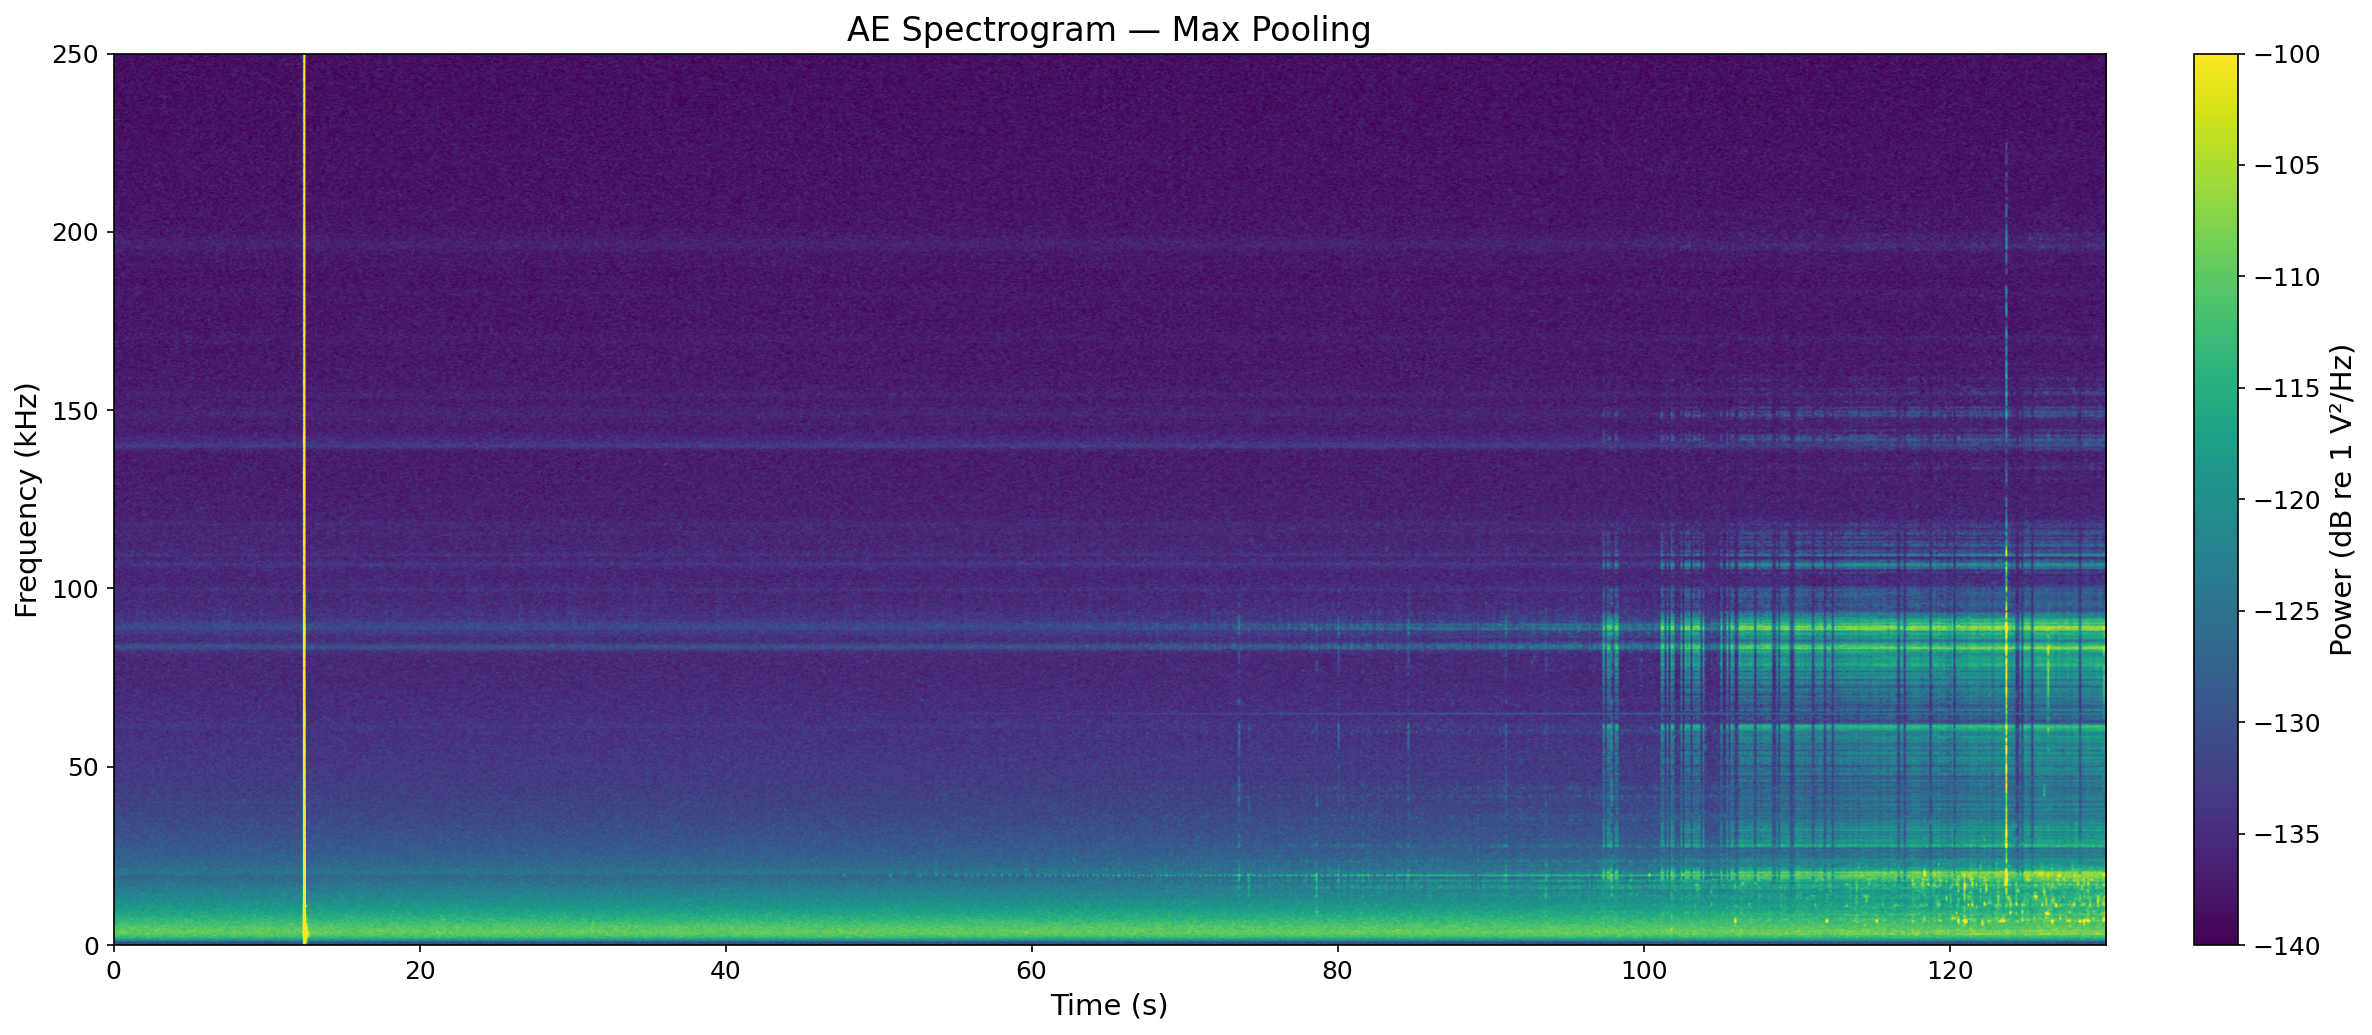

In [29]:
if "max" in db_by_mode:
    max_fig, max_ax = plot_spectrogram(
        frequencies,
        time_edges,
        db_by_mode["max"],
        title="AE Spectrogram — Max Pooling",
        vmin=max_vmin_db,
        vmax=max_vmax_db,
        **plot_settings,
    )
    plt.show()


## Mean-pooled spectrogram


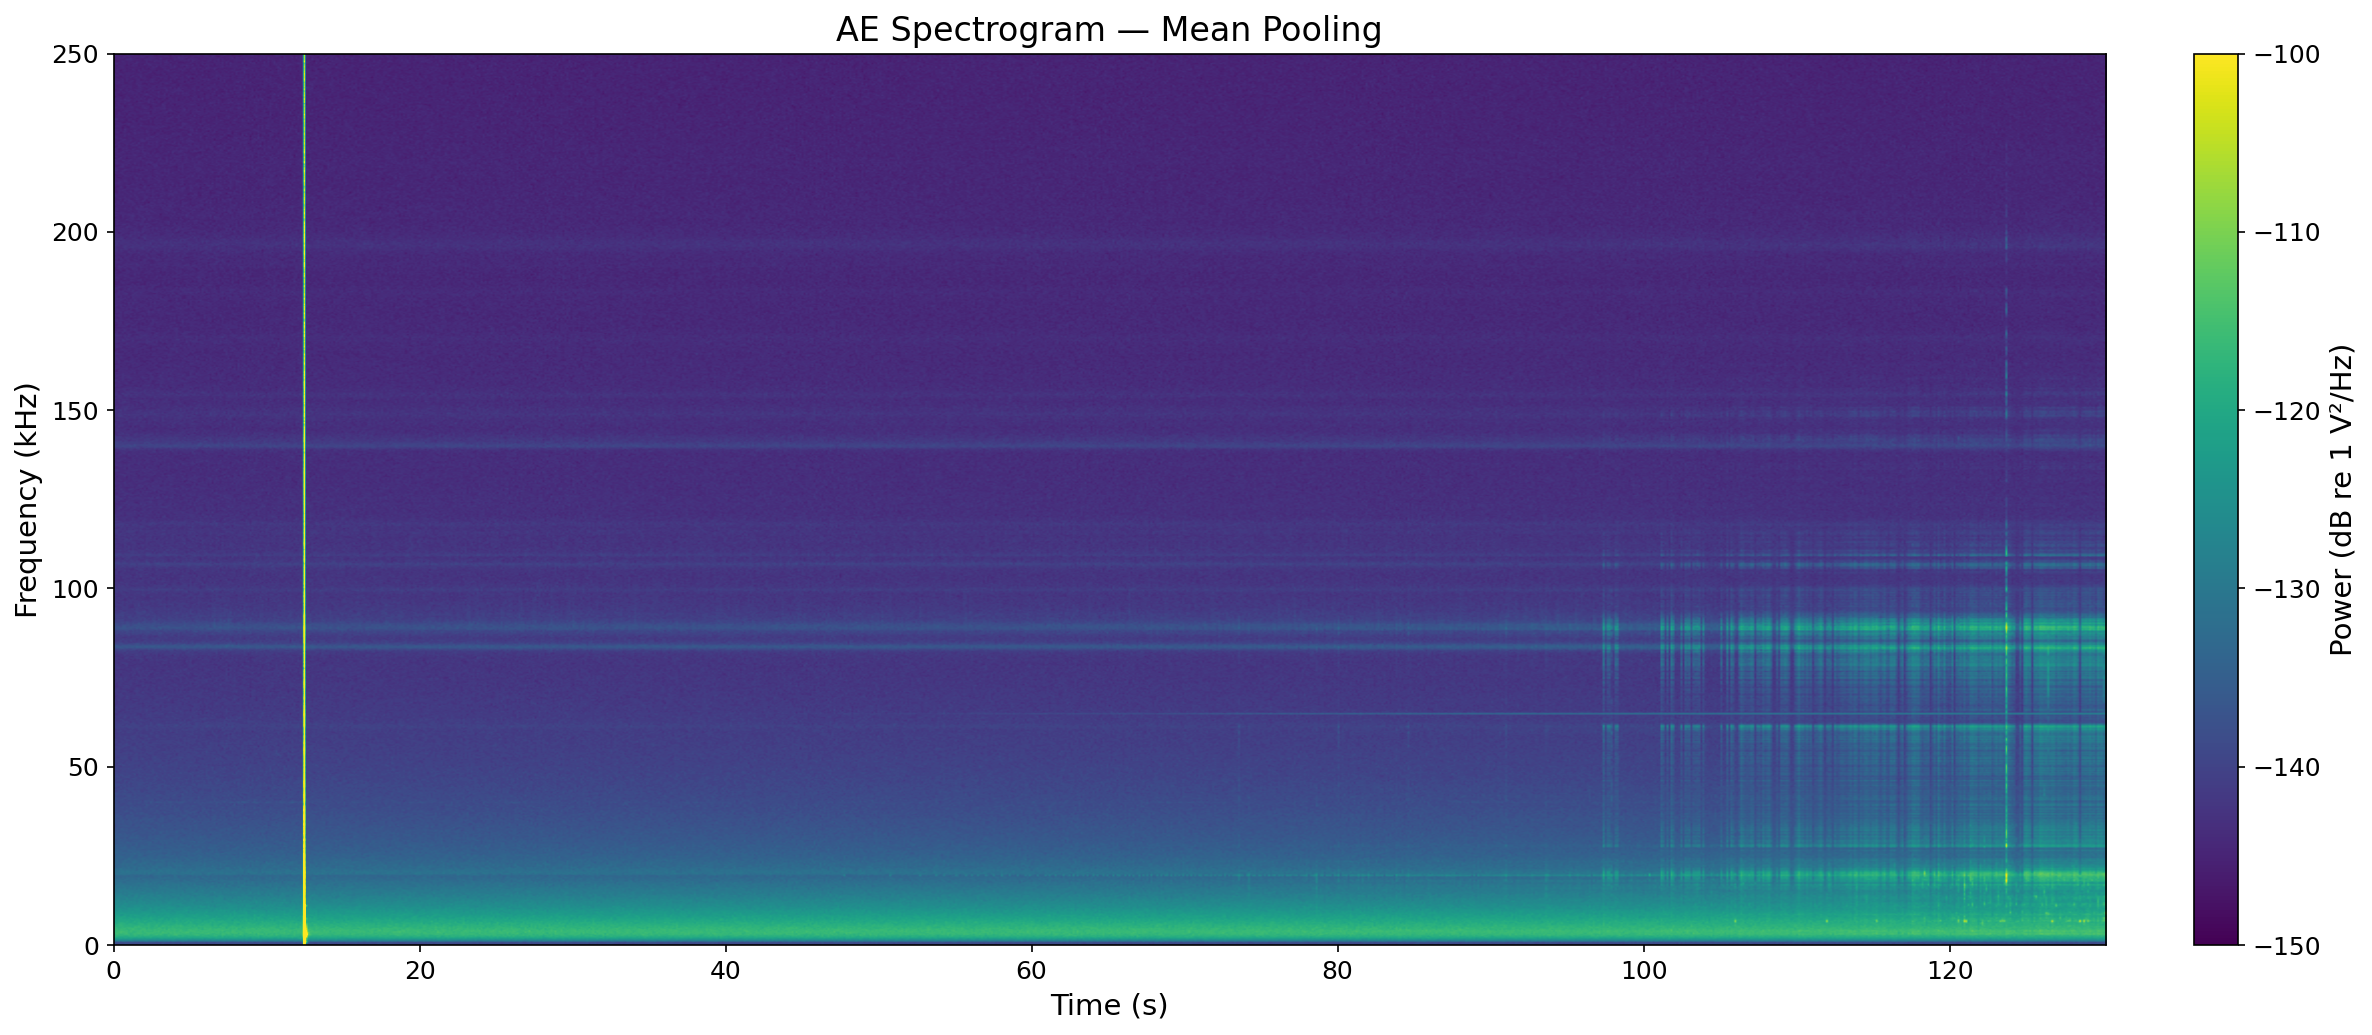

In [30]:
if "mean" in db_by_mode:
    mean_fig, mean_ax = plot_spectrogram(
        frequencies,
        time_edges,
        db_by_mode["mean"],
        title="AE Spectrogram — Mean Pooling",
        vmin=mean_vmin_db,
        vmax=mean_vmax_db,
        **plot_settings,
    )
    plt.show()
